# Qualidade e preparação dos dados

Esse notebook tem como finalidade o diagnóstico da base de dados de pedidos antes da análise exploratória de dados (EDA). Portanto, será investigada a estrutura, regras de negócio e coerência entre variáveis da base de dados.

*Observações*
- Cada decisão realizada será registrada no [registro de decisões](../reports/registro_decisoes.md)
- A base de dados tratada será gerada no final do notebook e salva em [../data/processed](../data/processed/)

In [1]:
# Importações
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from loguru import logger
from scipy import stats

# Logs do projeto desligados para não gravar caminhos da máquina local nas saídas
logger.disable("src")

from src.config import RANDOM_SEED
from src.dataset import download_raw_data

# Base bruta: baixada da fonte oficial na primeira execução e conferida pelo SHA-256 (D-01)
raw = pd.read_csv(download_raw_data())


## 1. Visão geral da base de dados

Nesta etapa, serão avaliadas a estrutura da base, os tipos de dados e as principais características estatísticas das variáveis, com foco na compreensão inicial dos dados e na identificação de possíveis inconsistências.

- **Dimensões:** quantidade de linhas e colunas.
- **Tipos de dados:** tipos de cada variável e adequação ao seu conteúdo.
- **Distribuição das notas:** escala, precisão decimal e estatísticas descritivas.
- **Observações iniciais:** padrões, valores atípicos e características relevantes identificadas.

In [2]:
print(f"{raw.shape[0]} pedidos e {raw.shape[1]} colunas")
raw.head()


2500 pedidos e 19 colunas


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


In [3]:
# Perfil de cada coluna: tipo, valores preenchidos, valores distintos e faixa
profile = pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "preenchidos": raw.notna().sum(),
    "distintos": raw.nunique(),
    "mínimo": raw.min(numeric_only=True),
    "máximo": raw.max(numeric_only=True),
}).reindex(raw.columns)
profile


,tipo,preenchidos,distintos,mínimo,máximo
customer_id,int64,2500,2500,1.00,2500.00
customer_age,int64,2500,52,18.00,69.00
customer_region,str,2500,5,NaN,NaN
customer_tenure_months,int64,2500,119,1.00,119.00
order_id,int64,2500,2500,50001.00,52500.00
order_value,float64,2500,2457,7.76,1983.81
items_quantity,int64,2500,6,1.00,6.00
discount_value,float64,2500,2050,0.02,230.33
payment_installments,int64,2500,11,1.00,11.00
delivery_time_days,int64,2500,13,2.00,14.00


In [4]:
# Distribuição das variáveis numéricas, sem os identificadores
raw.drop(columns=["customer_id", "order_id"]).describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
customer_age,2500.0,43.40,14.89,18.00,31.00,43.00,56.00,69.00
customer_tenure_months,2500.0,61.32,34.48,1.00,31.00,62.00,91.00,119.00
order_value,2500.0,434.26,289.77,7.76,220.24,375.52,577.29,1983.81
items_quantity,2500.0,3.47,1.69,1.00,2.00,3.00,5.00,6.00
discount_value,2500.0,29.75,29.23,0.02,8.88,20.94,40.83,230.33
payment_installments,2500.0,6.00,3.16,1.00,3.00,6.00,9.00,11.00
delivery_time_days,2500.0,8.02,3.77,2.00,5.00,8.00,11.00,14.00
delivery_delay_days,2500.0,2.19,1.45,0.00,1.00,2.00,3.00,8.00
freight_value,2500.0,38.22,12.08,2.62,29.93,38.50,46.27,76.13
delivery_attempts,2500.0,2.01,0.82,1.00,1.00,2.00,3.00,3.00


**A base segue o dicionário de dados: uma linha por pedido e tipos coerentes com o conteúdo de cada coluna.** A nota de NPS tem casa decimal, ao contrário da escala inteira do método, e por isso notas como 6,9 dependem da regra de corte de D-05, comparada ao arredondamento na seção 3. As notas se concentram abaixo de 7, e o detrator, que costuma ser minoria, aqui é a maior parte dos pedidos.

## 2. Diagnóstico de qualidade

Os critérios de cada verificação foram fixados antes da análise. O que cada achado significa para o tratamento é decidido na revisão do diagnóstico e resumido na seção 4.

### 2.1 Integridade

Valores ausentes, linhas e pedidos repetidos e clientes com mais de um pedido. Pedidos repetidos indicariam erro de carga; clientes repetidos mudariam a unidade de análise e a forma de separar treino e teste.

In [5]:
integrity = pd.Series(
    {
        "colunas com valor ausente": raw.isna().any().sum(),
        "linhas repetidas": raw.duplicated().sum(),
        "pedidos repetidos": raw["order_id"].duplicated().sum(),
        "clientes com mais de um pedido": raw["customer_id"].value_counts().gt(1).sum(),
    },
    name="quantidade",
)
integrity


colunas com valor ausente         0
linhas repetidas                  0
pedidos repetidos                 0
clientes com mais de um pedido    0
Name: quantidade, dtype: int64

**A base está completa e sem duplicidades, e cada cliente aparece em um único pedido.** Cliente e pedido são a mesma unidade de análise, e a separação entre treino e teste não precisa agrupar pedidos do mesmo cliente (D-06). Como todo pedido tem nota, a base não mostra quem deixou de responder à pesquisa, e as conclusões valem apenas para quem respondeu (premissa P4 do [entendimento do negócio](../reports/entendimento_negocio.md#7-premissas-restrições-e-riscos)).

### 2.2 Regras de negócio

Cada regra descreve algo que a base deveria respeitar: limites de cada variável, desconto até o valor do pedido, atraso entre zero e o tempo de entrega e coerência entre contatos, reclamações e tempo de resolução. A tabela conta os pedidos que violam cada uma.

In [6]:
# Cada regra é a condição que identifica os pedidos que a violam.
# Idade: da maioridade civil, 18 anos, até um teto plausível, 100 anos.
rules = {
    "nota fora de 0 a 10": "nps_score < 0 or nps_score > 10",
    "nota com mais de uma casa decimal": "nps_score.round(1) != nps_score",
    "recompra diferente de 0 e de 1": "repeat_purchase_30d not in (0, 1)",
    "idade fora de 18 a 100 anos": "customer_age < 18 or customer_age > 100",
    "valor monetário negativo": "order_value < 0 or discount_value < 0 or freight_value < 0",
    "contagem ou tempo negativo": (
        "customer_tenure_months < 0 or delivery_time_days < 0"
        " or customer_service_contacts < 0 or resolution_time_days < 0 or complaints_count < 0"
    ),
    "itens, tentativas ou parcelas abaixo de 1": (
        "items_quantity < 1 or delivery_attempts < 1 or payment_installments < 1"
    ),
    "desconto maior que o valor do pedido": "discount_value > order_value",
    "atraso negativo": "delivery_delay_days < 0",
    "atraso maior que o tempo de entrega": "delivery_delay_days > delivery_time_days",
    "mais reclamações que contatos": "complaints_count > customer_service_contacts",
    "tempo de resolução sem contato": (
        "customer_service_contacts == 0 and resolution_time_days > 0"
    ),
}
counts = {rule: len(raw.query(condition, engine="python")) for rule, condition in rules.items()}
violations = pd.DataFrame({"pedidos": counts})
violations["% da base"] = (violations["pedidos"] / len(raw) * 100).round(1)
violations


,pedidos,% da base
nota fora de 0 a 10,0,0.0
nota com mais de uma casa decimal,0,0.0
recompra diferente de 0 e de 1,0,0.0
idade fora de 18 a 100 anos,0,0.0
valor monetário negativo,0,0.0
contagem ou tempo negativo,0,0.0
"itens, tentativas ou parcelas abaixo de 1",0,0.0
desconto maior que o valor do pedido,35,1.4
atraso negativo,0,0.0
atraso maior que o tempo de entrega,121,4.8


**Isoladamente, todas as variáveis respeitam suas faixas válidas, e os problemas surgem quando duas colunas são comparadas.** Com o tempo de entrega lido como previsão, e não como o tempo total suposto na premissa P3, o atraso maior que ele deixa de ser incoerência: são entregas que levaram mais que o dobro do previsto. Desconto acima do valor do pedido é raro; já os registros de atendimento se contradizem com frequência, e quase todo pedido tem mais reclamações que contatos.

### 2.3 Pedidos que violam as regras

Amostra de pedidos de cada regra violada, só com as colunas que a regra usa. Poucos casos isolados sugerem erro de registro; muitos casos ou um padrão sugerem que o dado não corresponde à descrição do dicionário.

In [7]:
# Até cinco pedidos por regra violada, sorteados com semente fixa para o resultado ser reproduzível
for rule, condition in rules.items():
    violating = raw.query(condition, engine="python")
    if violating.empty:
        continue
    columns = [column for column in raw.columns if column in condition]
    print(f"\n{rule}: {len(violating)} pedidos")
    display(
        violating[["order_id", *columns]].sample(min(5, len(violating)), random_state=RANDOM_SEED)
    )



desconto maior que o valor do pedido: 35 pedidos


,order_id,order_value,discount_value
1714,51715,27.48,35.83
798,50799,55.54,71.45
1621,51622,64.87,83.33
1266,51267,37.17,52.52
880,50881,7.76,29.21



atraso maior que o tempo de entrega: 121 pedidos


,order_id,delivery_time_days,delivery_delay_days
909,50910,2,3
933,50934,2,6
58,50059,2,3
1111,51112,3,4
480,50481,4,5



mais reclamações que contatos: 2428 pedidos


,order_id,customer_service_contacts,complaints_count
976,50977,0,2
1218,51219,0,1
596,50597,0,5
492,50493,2,5
1651,51652,1,3



tempo de resolução sem contato: 511 pedidos


,order_id,customer_service_contacts,resolution_time_days
665,50666,0,3
409,50410,0,9
2139,52140,0,3
1281,51282,0,5
356,50357,0,6


**As violações seguem padrões e apontam para o significado das colunas, e não para erros de digitação.** Na amostra, o desconto supera o valor em pedidos baratos, o que faz sentido se o valor do pedido já for líquido do desconto, e o atraso supera a previsão nos prazos curtos, os mais fáceis de estourar. Reclamações e tempo de resolução registrados em pedidos sem nenhum contato indicam que essas colunas não descrevem só o atendimento daquele pedido (premissa P2).

### 2.4 Valores extremos

Valores fora dos limites de Tukey, abaixo de Q1 - 1,5 x IQR ou acima de Q3 + 1,5 x IQR, nas variáveis numéricas, exceto identificadores e indicadores de 0 ou 1. Um extremo plausível para o negócio fica na base, porque costuma representar justamente a experiência que mais importa.

In [8]:
numeric = raw.select_dtypes("number").drop(columns=["customer_id", "order_id"])
numeric = numeric.loc[:, numeric.nunique() > 2]  # indicadores 0 ou 1 ficam de fora
q1, q3 = numeric.quantile(0.25), numeric.quantile(0.75)
lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
outliers = pd.DataFrame(
    {
        "limite inferior": lower,
        "limite superior": upper,
        "mínimo": numeric.min(),
        "máximo": numeric.max(),
        "pedidos fora": (numeric.lt(lower) | numeric.gt(upper)).sum(),
    }
).round(2)
outliers = outliers[outliers["pedidos fora"] > 0]
outliers


,limite inferior,limite superior,mínimo,máximo,pedidos fora
order_value,-315.32,1112.86,7.76,1983.81,84
discount_value,-39.04,88.75,0.02,230.33,125
delivery_delay_days,-2.00,6.00,0.00,8.00,17
freight_value,5.41,70.78,2.62,76.13,12
customer_service_contacts,-0.50,3.50,0.00,7.00,176
complaints_count,0.00,8.00,0.00,11.00,29


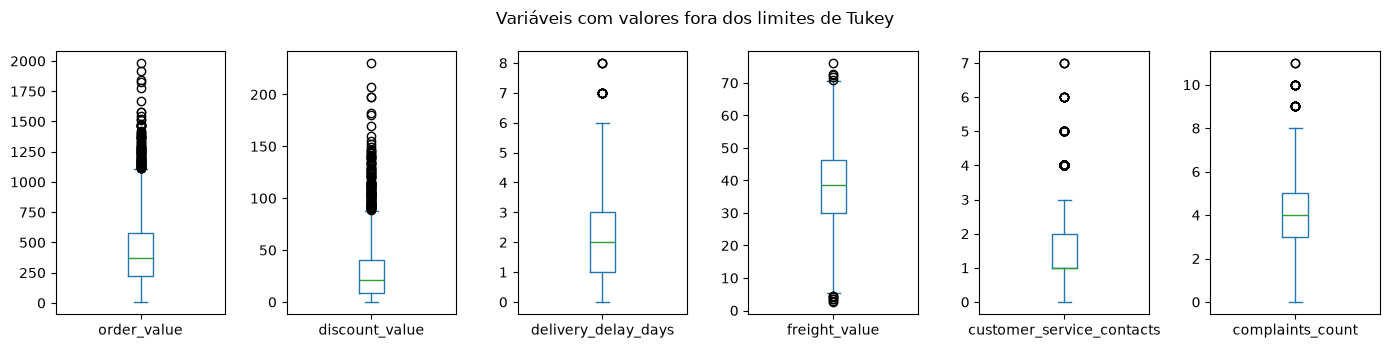

In [9]:
if not outliers.empty:
    raw[outliers.index].plot.box(subplots=True, layout=(1, len(outliers)), figsize=(14, 3.5))
    plt.suptitle("Variáveis com valores fora dos limites de Tukey")
    plt.tight_layout()
    plt.show()


**Os extremos são plausíveis para o negócio: pedidos caros, descontos altos, fretes fora do comum, atrasos longos e clientes com muitos contatos e reclamações.** Eles prolongam a cauda de cada distribuição, sem saltos que sugiram erro de registro. Nas contagens, a faixa central estreita faz a regra de Tukey tratar como extremo o que é só a cauda natural.

### 2.5 Padronização das regiões

Grafias diferentes para a mesma região, por espaços ou maiúsculas, dividiriam uma região em duas nas análises. A verificação compara o número de grafias antes e depois de padronizar.

In [10]:
regions = raw["customer_region"]
standardized = regions.str.strip().str.casefold()
print("Grafias distintas:", regions.nunique(), "| depois de padronizar:", standardized.nunique())
regions.value_counts()


Grafias distintas: 5 | depois de padronizar: 5


customer_region
Sul             521
Sudeste         520
Norte           506
Nordeste        485
Centro-Oeste    468
Name: count, dtype: int64

**Não há grafias diferentes para a mesma região, e a coluna já está padronizada.** Os pedidos se dividem quase por igual entre as cinco regiões, um retrato improvável para o comércio eletrônico brasileiro, que se concentra no Sudeste. Esse equilíbrio é um dos sinais avaliados na 2.6.

### 2.6 Sinais de base simulada

Dados de operação real têm assimetrias e relações esperadas entre variáveis. Distribuições planas demais, relações ausentes onde o negócio espera encontrá-las e relações fortes demais indicam dados gerados artificialmente. O resultado define o alcance das conclusões do projeto (premissa P5 do [entendimento do negócio](../reports/entendimento_negocio.md#7-premissas-restrições-e-riscos)).

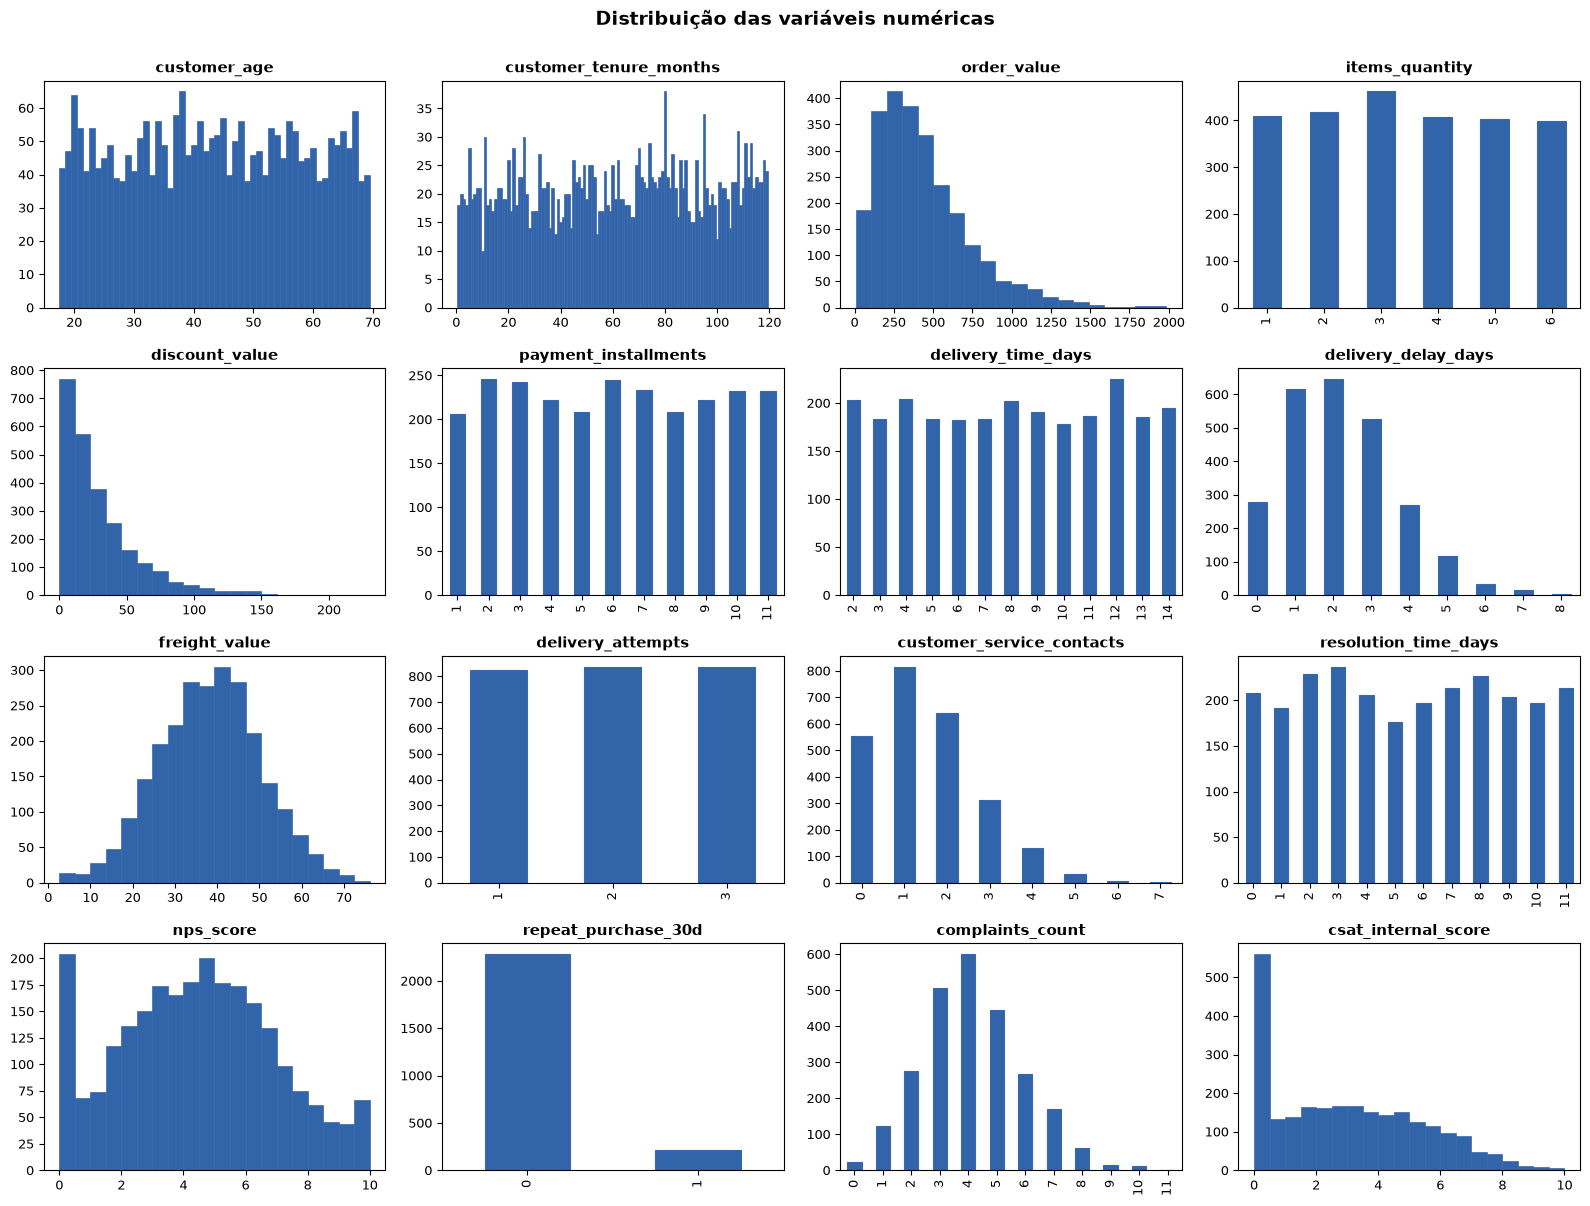

In [11]:
# Variáveis com até 20 valores em barras; as demais em histogramas
variables = raw.drop(columns=["customer_id", "order_id"]).select_dtypes("number")

n_rows = int(np.ceil(variables.shape[1] / 4))
fig, axes = plt.subplots(n_rows, 4, figsize=(16, 3 * n_rows))
axes = np.asarray(axes).flatten()

for ax, column in zip(axes, variables.columns):
    values = variables[column]

    if values.nunique() <= 20:
        values.value_counts().sort_index().plot.bar(
            ax=ax,
            color="#3164A8",
            edgecolor="#3B67AD",
            linewidth=0.8,
        )
    elif pd.api.types.is_integer_dtype(values):
        # Inteiros com muitos valores: uma barra por valor
        values.plot.hist(
            ax=ax,
            bins=np.arange(values.min(), values.max() + 2) - 0.5,
            color="#3164A8",
            edgecolor="#3B67AD",
            linewidth=0.5,
        )
    else:
        values.plot.hist(
            ax=ax,
            bins=20,
            color="#3164A8",
            edgecolor="#3B67AD",
            linewidth=0.5,
        )

    ax.set_title(column, fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="both", labelsize=9)

for ax in axes[variables.shape[1]:]:
    ax.set_visible(False)

plt.suptitle(
    "Distribuição das variáveis numéricas",
    fontsize=14,
    fontweight="bold",
    y=1.001,
)

plt.tight_layout()
plt.show()


In [12]:
# Qui-quadrado de aderência à distribuição uniforme, nas variáveis com até 20 valores.
# p-valor alto: as frequências não se afastam de valores igualmente prováveis.
discrete = [
    column
    for column in raw.columns.drop(["customer_id", "order_id"])
    if raw[column].nunique() <= 20
]
uniformity = pd.DataFrame(
    {
        "valores distintos": [raw[column].nunique() for column in discrete],
        "p-valor": [stats.chisquare(raw[column].value_counts()).pvalue for column in discrete],
    },
    index=discrete,
).round(3)
uniformity


,valores distintos,p-valor
customer_region,5,0.373
items_quantity,6,0.270
payment_installments,11,0.478
delivery_time_days,13,0.542
delivery_delay_days,9,0.000
delivery_attempts,3,0.925
customer_service_contacts,8,0.000
resolution_time_days,12,0.158
repeat_purchase_30d,2,0.000
complaints_count,12,0.000


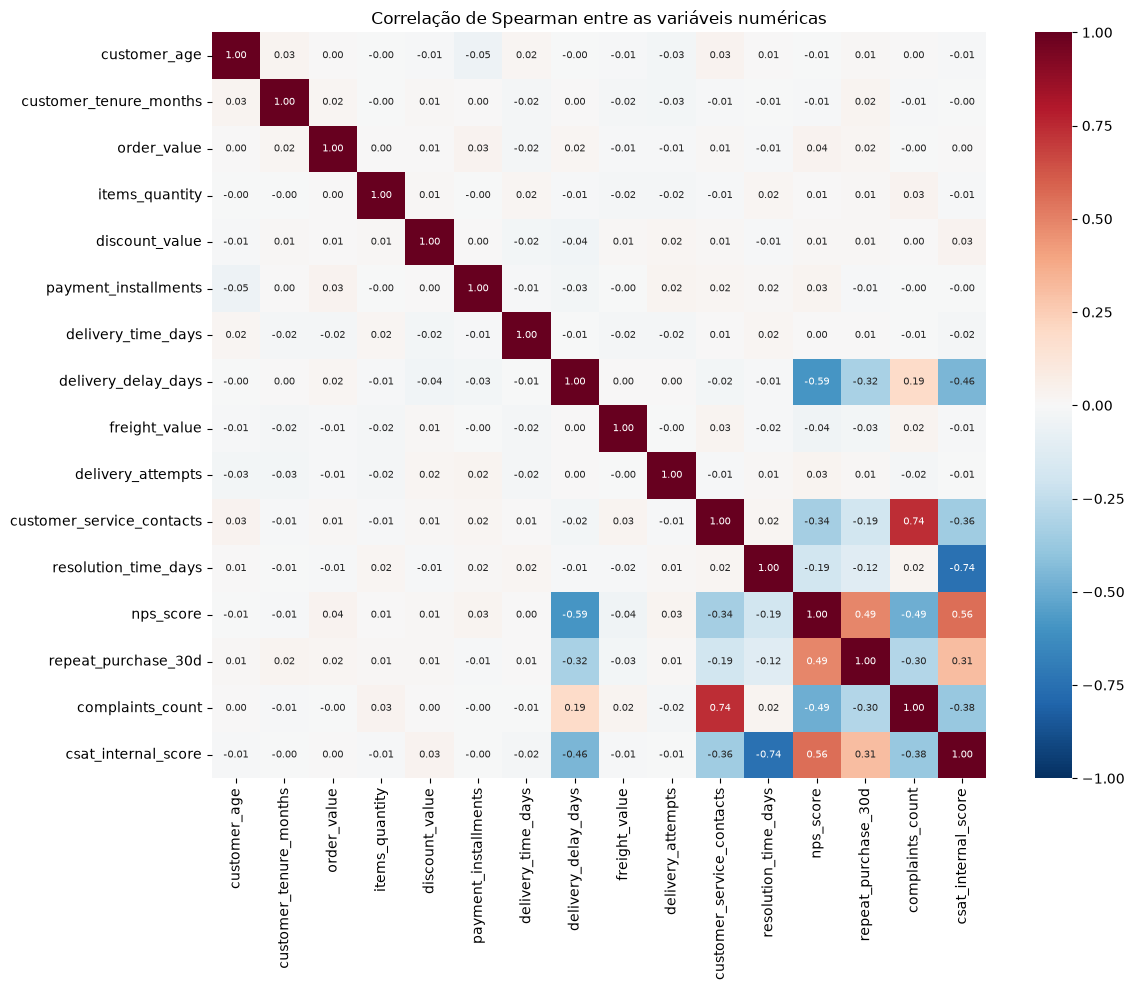

In [13]:
plt.figure(figsize=(12, 10))
sns.heatmap(
    variables.corr(method="spearman"),
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
)
plt.title("Correlação de Spearman entre as variáveis numéricas")
plt.tight_layout()
plt.show()


**A base tem os sinais típicos de dados simulados: distribuições planas e relações esperadas que não aparecem.** Idade, itens, parcelas, tentativas de entrega e região se distribuem quase por igual; o valor do pedido não acompanha itens nem desconto, e o atraso não traz mais tentativas de entrega nem mais contatos com o atendimento. Pela premissa P5, as conclusões do projeto passam a valer como demonstração de método, e não como retrato de uma operação real.